In [48]:
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.image as mpimg
from scipy import ndimage


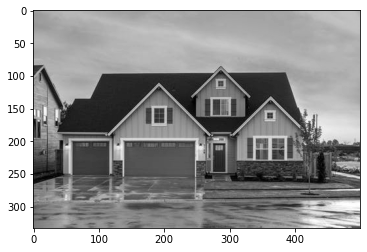

In [49]:

def rgb2gray(rgb):
    return np.dot(rgb[...,:3], [0.299, 0.587, 0.144])

img = mpimg.imread('res/hs.jpg')

gray = rgb2gray(img)

plt.imshow(gray, cmap = plt.get_cmap('gray'))
plt.show()

(333, 500)


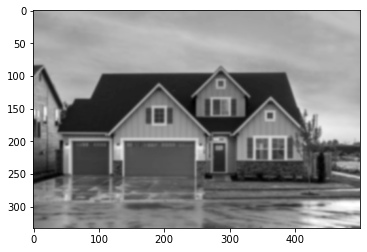

In [50]:
camera_blurred = ndimage.gaussian_filter(gray, sigma=1.4)
print(camera_blurred.shape)
plt.imshow(camera_blurred, cmap = plt.get_cmap('gray'))
plt.show()

In [51]:
def sobelFilter(img, filterDirection):
    '''
    SobelFilter(image, gradient)

    colvolves the image with Sobel filters and returns ndimage.
    '''
    if( filterDirection == 'x'):
        Gx = np.array([[-1, 0, +1], [-2, 0, +2], [-1, 0, +1]])
        convolved = ndimage.convolve(img, Gx)
    elif( filterDirection == 'y'):
        Gy = np.array([[-1, -2, -1], [0, 0, 0], [+1, +2, +1]])
        convolved = ndimage.convolve(img, Gy)
    return convolved

In [52]:
# Normalize the pixel to <= 1
def Normalize(img):
    img = img/np.max(img)
    return img

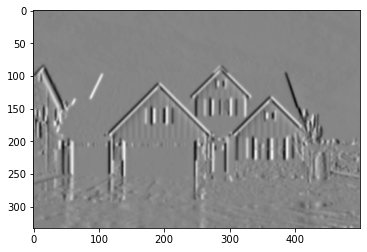

In [53]:
# Apply Sobel filter in X - direction (Gx)
vertical_edge = sobelFilter(camera_blurred, 'x')
vertical_edge = Normalize(vertical_edge)
plt.imshow(vertical_edge, cmap = plt.get_cmap('gray'))
plt.show()

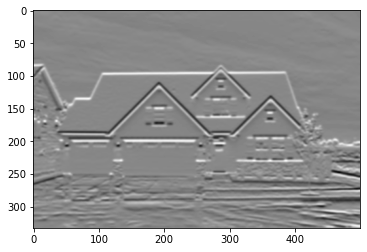

In [54]:
# Apply Sobel filter in Y - direction (Gy)
horizontal_edge = sobelFilter(camera_blurred, 'y')
horizontal_edge = Normalize(horizontal_edge)
plt.imshow(horizontal_edge, cmap = plt.get_cmap('gray'))
plt.show()

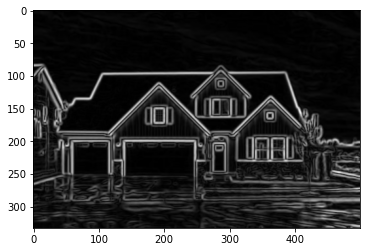

In [55]:
# Calculate the magnitude G = sqrt(gx^2 + gy^2)
magnitude = np.hypot(horizontal_edge, vertical_edge)
magnitude = Normalize(magnitude)
plt.imshow(magnitude, cmap= plt.get_cmap('gray'))
plt.show()

In [56]:
# Calculate angle
# theta = arctan(Gy / Gx)
# arctan2 return arctan(Gy / Gx) randian in between -pi to pi and is converted to degree 
theta = np.degrees(np.arctan2( horizontal_edge, vertical_edge ))


In [57]:
# Perform Non-Maximum supression without interpolation
def NonMaxSupWithoutInterpol(g_mag, grad):
    '''
    NonMaxSupWithoutInterpol(g_mag, grad)

    supreses the pixel that is not grater than it's neighbour.
    neighbours are selected based on the gradient angle.

    returns numpy array 
    '''
    NMS = np.zeros(g_mag.shape)
    for i in range(1, g_mag.shape[0] - 1):
        for j in range(1, g_mag.shape[1] - 1):
            # Left, Right
            if( (grad[i, j] >= -22.5 and grad[i, j] <= 22.5) or (grad[i, j] >= 157.5 and grad[i, j] <= -157.5) ):
                if( g_mag[i, j] > g_mag[i, j+1] and g_mag[i, j] > g_mag[i, j-1] ):
                    NMS[i, j] = g_mag[i, j]
                else:
                    # Set black
                    NMS[i, j] = 0
            # Top right, Bottom left
            elif( (grad[i, j] >= 22.5 and grad[i, j] <= 67.5) or (grad[i, j] >= -157.5 and grad[i, j] <= -112.5) ):
                if( g_mag[i, j] > g_mag[i-1, j+1] and g_mag[i, j] > g_mag[i+1, j-1] ):
                    NMS[i, j] = g_mag[i, j]
                else:
                    NMS[i, j] = 0
            # Top, bottom
            elif( (grad[i, j] >= 67.5 and grad[i, j] <= 112.5) or (grad[i, j] >= -112.5 and grad[i, j] <= -67.5) ):
                if( g_mag[i, j] > g_mag[i-1, j] and g_mag[i, j] > g_mag[i+1, j] ):
                    NMS[i, j] = g_mag[i, j]
                else:
                    NMS[i, j] = 0
            # Top left, bottom right 
            elif( (grad[i, j] >= 112.5 and grad[i, j] <= 157.5) or (grad[i, j] >= -67.5 and grad[i, j] <= -22.5) ):
                if( g_mag[i, j] > g_mag[i-1, j-1] and g_mag[i, j] > g_mag[i+1, j+1] ):
                    NMS[i, j] = g_mag[i, j]
                else:
                    NMS[i, j] = 0
    return NMS



<function matplotlib.pyplot.show(close=None, block=None)>

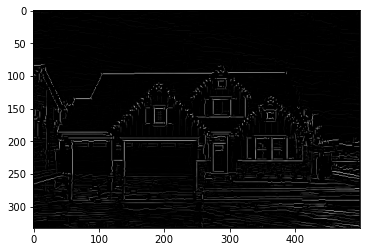

In [58]:
NMS = NonMaxSupWithoutInterpol(magnitude, theta)
NMS = Normalize(NMS)
plt.imshow(NMS, cmap = plt.get_cmap('gray'))
plt.show

In [59]:
# NMS with interpolation
def NonMaxSuppressionWithInterpol(g_mag, grad, g_x, g_y):
    '''
    NonMaxSuppressionWithInterpol(g_mag, grad, g_x, g_y)

    supreses the pixel that is not grater than it's neighbour.
    neighbour values are selected with interpolation.

    returns numpy array
    '''
    NMS = np.zeros(g_mag.shape)

    for i in range(1, g_mag.shape[0] - 1):
        for j in range(1, g_mag.shape[1] - 1):
            # 0 <= gradient < 45 and  180 <= gradient < -135
            if( (grad[i, j] >= 0 and grad[i, j] <= 45) or (grad[i, j] >= 180 and grad[i, j] < -135) ):
                # y = [y0, y1]
                # y0 = y[a,b], if it is at top or bottom or left or right
                # y1 = y[a,b], otherwise
                y_bot = np.array( [ g_mag[i, j+1], g_mag[i+1, j+1] ] )
                y_top = np.array( [ g_mag[i, j-1], g_mag[i-1, j-1] ] )
                # As we are interpolating in Y direction
                # sin (theta) = y / magnitude
                x_est = np.absolute( g_y[i, j] / g_mag[i, j] )

                #                   (magnitude along Y)sin(theta) + offset
                if(g_mag[i,j] >= ( (y_bot[1]-y_bot[0])*x_est + y_bot[0] ) and g_mag[i, j] >= ( (y_top[1]-y_top[0])*x_est + y_top[0] ) ):
                    NMS[i,j] = g_mag[i,j]
                else:
                    NMS[i,j] = 0
            # 45 <= gradient < 90 and  -135 <= gradient < -90
            if( (grad[i, j] >= 45 and grad[i, j] <= 90) or (grad[i, j] >= -135 and grad[i, j] < -90) ):
                y_bot = np.array( [ g_mag[i+1, j], g_mag[i+1, j+1] ] )
                y_top = np.array( [ g_mag[i-1, j], g_mag[i-1, j-1] ] )
                # As we are interpolating in X direction
                # cos(theta) = x / magnitude
                x_est = np.absolute( g_x[i, j] / g_mag[i, j] )

                #                   (magnitude along X)cos(theta) + offset
                if(g_mag[i,j] >= ( (y_bot[1]-y_bot[0])*x_est + y_bot[0] ) and g_mag[i, j] >= ( (y_top[1]-y_top[0])*x_est + y_top[0] ) ):
                    NMS[i,j] = g_mag[i,j]
                else:
                    NMS[i,j] = 0
             # 90 <= gradient < 135 and  -90 <= gradient < -45
            if( (grad[i, j] >= 90 and grad[i, j] <= 135) or (grad[i, j] >= -90 and grad[i, j] < -45) ):
                y_bot = np.array( [ g_mag[i+1, j], g_mag[i+1, j-1] ] )
                y_top = np.array( [ g_mag[i-1, j], g_mag[i-1, j+1] ] )
                # cos(theta) = x / magnitude
                x_est = np.absolute( g_x[i, j] / g_mag[i, j] )
                if(g_mag[i,j] >= ( (y_bot[1]-y_bot[0])*x_est + y_bot[0] ) and g_mag[i, j] >= ( (y_top[1]-y_top[0])*x_est + y_top[0] ) ):
                    NMS[i,j] = g_mag[i,j]
                else:
                    NMS[i,j] = 0
             # 135 <= gradient < 180 and  -45 <= gradient < 0
            if( (grad[i, j] >= 135 and grad[i, j] <= 180) or (grad[i, j] >= -45 and grad[i, j] < 360) ):
                y_bot = np.array( [ g_mag[i, j-1], g_mag[i+1, j-1] ] )
                y_top = np.array( [ g_mag[i, j+1], g_mag[i-1, j+1] ] )
                x_est = np.absolute( g_y[i, j] / g_mag[i, j] )
                if(g_mag[i,j] >= ( (y_bot[1]-y_bot[0])*x_est + y_bot[0] ) and g_mag[i, j] >= ( (y_top[1]-y_top[0])*x_est + y_top[0] ) ):
                    NMS[i,j] = g_mag[i,j]
                else:
                    NMS[i,j] = 0
    return NMS                


<function matplotlib.pyplot.show(close=None, block=None)>

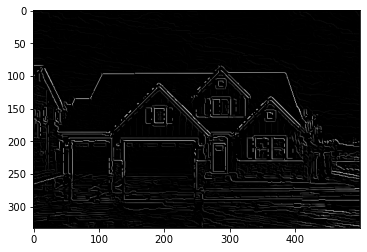

In [60]:
NMS = NonMaxSuppressionWithInterpol(magnitude, theta, vertical_edge ,horizontal_edge)
NMS = Normalize(NMS)
plt.imshow(NMS, cmap = plt.get_cmap('gray'))
plt.show

In [61]:
def double_threshold(img, low_threshold=0.05, high_threshold=0.09):
    high_threshold = img.max() * high_threshold_ratio
    low_threshold = high_threshold * low_threshold_ratio

    res = np.zeros(img.shape)

    weak = np.int32(25)
    strong = np.int32(255)

    strong_row, strong_col = np.where(img >= high_threshold)
    zeros_row, zeros_col = np.where(img < low_threshold)

    weak_row, weak_col = np.where((img <= high_threshold) & (img >= low_threshold))

    res[strong_row, strong_col] = strong
    res[weak_row, weak_col] = weak

    return res


In [62]:

def hysteresis(img, weak=25, strong=255):
    M, N = img.shape  
    for i in range(1, M-1):
        for j in range(1, N-1):
            if (img[i,j] == weak):
                try:
                    if ((img[i+1, j-1] == strong) or (img[i+1, j] == strong) or (img[i+1, j+1] == strong)
                        or (img[i, j-1] == strong) or (img[i, j+1] == strong)
                        or (img[i-1, j-1] == strong) or (img[i-1, j] == strong) or (img[i-1, j+1] == strong)):
                        img[i, j] = strong
                    else:
                        img[i, j] = 0
                except IndexError as e:
                    pass
    return img

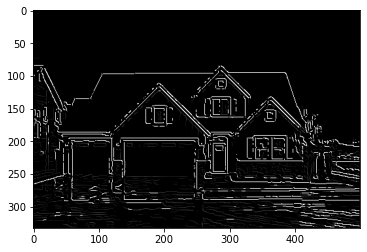

In [63]:
final_image = double_thresholding(NMS)
final_image = hysteresis(final_image)
final_image = Normalize(final_image)
plt.imshow(final_image, cmap = plt.get_cmap('gray'))
plt.show()